# Day 7 — Multiclass Image Classification & Transfer Learning
**System 7 · Week 3 · Commit: `day-21-image-classifier`**

**Module D:** multiclass classification, transfer learning with a pretrained model, evaluation and prediction visualisation.

**Practice question solved today:** Q18 · **Module task:** an image classifier for different objects and animals (CIFAR-10: 10 classes) · **Learning topic:** Transfer learning

In [1]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score
warnings.filterwarnings("ignore")
RANDOM_STATE = 42; keras.utils.set_random_seed(RANDOM_STATE); R = {}
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
IMG = 96            # MobileNetV2 accepts 96x96 and up; CIFAR images are upscaled from 32x32

I0000 00:00:1793519086.493865     163 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793519105.885871     163 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
try:
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data(); y_train, y_test = y_train.ravel(), y_test.ravel(); source = "keras.datasets.cifar10"
except Exception:
    d = np.load("/home/claude/data/cifar10.npz"); x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    perm = np.random.default_rng(RANDOM_STATE).permutation(len(x_train)); x_train, y_train = x_train[perm], y_train[perm]; source = "offline copy of CIFAR-10 images"
print("Data:", source, "|", x_train.shape, x_test.shape)

Data: offline copy of CIFAR-10 images | (50000, 32, 32, 3) (10000, 32, 32, 3)


## Multiclass classification — what changes from binary
* The output layer has **one neuron per class** with **softmax** activation → a probability distribution over the 10 classes.
* Loss = **categorical cross-entropy** (`sparse_categorical_crossentropy` when labels are integers 0–9).
* Evaluation: overall accuracy, **per-class precision/recall/F1**, and a **confusion matrix**, because one class can be bad while the average looks fine.

## Learning topic — Transfer learning
Training a deep CNN from scratch needs lots of data and compute. **Transfer learning** re-uses a network (here **MobileNetV2**) that was already trained on ImageNet (1.4 million images, 1,000 classes). Its early layers know generic things — edges, textures, shapes — that are useful for almost any picture.
* **Feature extraction:** *freeze* the pretrained base (its weights do not change) and train only a small new classification head on top. Fast, safe with little data.
* **Fine-tuning:** afterwards *unfreeze* the top layers of the base and keep training with a **very small learning rate** so the high-level features adapt to the new task. Better accuracy, but more compute and a risk of overfitting/forgetting if the rate is too high.

## Q18 (Hard) — MobileNetV2 with a frozen base, compared with the CNN from scratch
**Setup:** data is split into 45,000 train / 5,000 validation; the 10,000 test images stay untouched. Images are upscaled to 96×96 and passed through MobileNetV2's own preprocessing (pixels → [−1, 1]).

In [3]:
def build_transfer():
    try:
        base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet"); w = "imagenet (downloaded by Keras)"
    except Exception:
        base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights=None)
        base.load_weights("/home/claude/data/mobilenet_v2_notop.h5"); w = "imagenet (offline copy of the same weights)"
    base.trainable = False                                                  # <-- FROZEN
    inputs = keras.Input((32, 32, 3))
    x = layers.Resizing(IMG, IMG)(inputs)
    x = layers.RandomFlip("horizontal")(x)
    x = keras.applications.mobilenet_v2.preprocess_input(x)                 # scale to [-1, 1]
    x = base(x, training=False)                                             # keep BatchNorm layers in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base, w

tl, base, weights_src = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
trainable = sum(int(np.prod(v.shape)) for v in tl.trainable_weights); total = tl.count_params()
print("Pretrained weights:", weights_src)
print(f"Total parameters: {total:,} | trainable (new head only): {trainable:,} | frozen base: {total - trainable:,}")
R["setup"] = {"weights": weights_src, "total_params": total, "trainable_params": trainable}

Pretrained weights: imagenet (offline copy of the same weights)
Total parameters: 2,270,794 | trainable (new head only): 12,810 | frozen base: 2,257,984


In [4]:
t0 = time.time()
h1 = tl.fit(x_train, y_train, validation_split=0.1, epochs=4, batch_size=128, verbose=2)
t_frozen = time.time() - t0; print(f"\nFrozen-base training time: {t_frozen/60:.1f} min")
loss1, acc1 = tl.evaluate(x_test, y_test, verbose=0); print(f"TEST accuracy (frozen base): {acc1:.4f}")

Epoch 1/4


352/352 - 151s - 428ms/step - accuracy: 0.5379 - loss: 1.5226 - val_accuracy: 0.6914 - val_loss: 0.9040


Epoch 2/4


352/352 - 144s - 410ms/step - accuracy: 0.6484 - loss: 1.0609 - val_accuracy: 0.7098 - val_loss: 0.8460


Epoch 3/4


352/352 - 135s - 382ms/step - accuracy: 0.6667 - loss: 0.9831 - val_accuracy: 0.7210 - val_loss: 0.8133


Epoch 4/4


352/352 - 130s - 369ms/step - accuracy: 0.6757 - loss: 0.9447 - val_accuracy: 0.7198 - val_loss: 0.7983



Frozen-base training time: 9.5 min


TEST accuracy (frozen base): 0.7166


### Optional step — fine-tuning the top of the base
Unfreeze the last ~30 layers of MobileNetV2 and continue with a learning rate 100× smaller. (BatchNorm layers stay in inference mode because the base is called with `training=False`.)

In [5]:
base.trainable = True
for layer in base.layers[:-30]: layer.trainable = False
tl.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])     # re-compile after changing trainable!
print("Trainable parameters now:", sum(int(np.prod(v.shape)) for v in tl.trainable_weights))
t0 = time.time()
h2 = tl.fit(x_train, y_train, validation_split=0.1, epochs=3, batch_size=128, verbose=2)
t_ft = time.time() - t0; print(f"\nFine-tuning time: {t_ft/60:.1f} min")
loss2, acc2 = tl.evaluate(x_test, y_test, verbose=0); print(f"TEST accuracy (after fine-tuning): {acc2:.4f}")
tl.save("mobilenetv2_cifar10.keras")

Trainable parameters now: 1539210
Epoch 1/3


352/352 - 189s - 537ms/step - accuracy: 0.6607 - loss: 0.9937 - val_accuracy: 0.7382 - val_loss: 0.7865


Epoch 2/3


352/352 - 201s - 572ms/step - accuracy: 0.7237 - loss: 0.8008 - val_accuracy: 0.7490 - val_loss: 0.7426


Epoch 3/3


352/352 - 304s - 862ms/step - accuracy: 0.7531 - loss: 0.7110 - val_accuracy: 0.7638 - val_loss: 0.6998



Fine-tuning time: 11.6 min


TEST accuracy (after fine-tuning): 0.7592


### The CNN from scratch (Day 6) for comparison
Loaded from Day 6's folder if it exists; otherwise the same architecture is trained here.

In [6]:
path = "../day-20-cnn-basics/cnn_cifar10.keras"
if os.path.exists(path):
    cnn = keras.models.load_model(path); print("Loaded the CNN trained on Day 6"); cnn_minutes = None
else:
    def conv_block(f, two=True):
        L = [layers.Conv2D(f, 3, padding="same", activation="relu"), layers.BatchNormalization()]
        if two: L += [layers.Conv2D(f, 3, padding="same", activation="relu"), layers.BatchNormalization()]
        return L + [layers.MaxPooling2D(2), layers.Dropout(0.25)]
    cnn = keras.Sequential([layers.Input((32, 32, 3)), layers.Rescaling(1/255), layers.RandomFlip("horizontal"), layers.RandomTranslation(0.08, 0.08)] + conv_block(32, False) + conv_block(64) + conv_block(128)
                           + [layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dropout(0.4), layers.Dense(10, activation="softmax")])
    cnn.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"]); t0 = time.time(); cnn.fit(x_train, y_train, validation_split=.1, epochs=12, batch_size=64, verbose=0); cnn_minutes = (time.time()-t0)/60
p_cnn = cnn.predict(x_test, verbose=0); p_frozen_ft = tl.predict(x_test, verbose=0)
pred_cnn, pred_tl = p_cnn.argmax(1), p_frozen_ft.argmax(1)
print(f"Scratch CNN TEST accuracy: {accuracy_score(y_test, pred_cnn):.4f}  | MobileNetV2 fine-tuned: {accuracy_score(y_test, pred_tl):.4f}")

Loaded the CNN trained on Day 6


Scratch CNN TEST accuracy: 0.7681  | MobileNetV2 fine-tuned: 0.7592


                           Test accuracy  Macro F1  Trainable params Train time (min)
CNN from scratch (Day 6)          0.7681    0.7662            542986        see Day 6
MobileNetV2 — frozen base         0.7166       NaN             12810              9.5
MobileNetV2 — fine-tuned          0.7592    0.7573           1539210             21.1


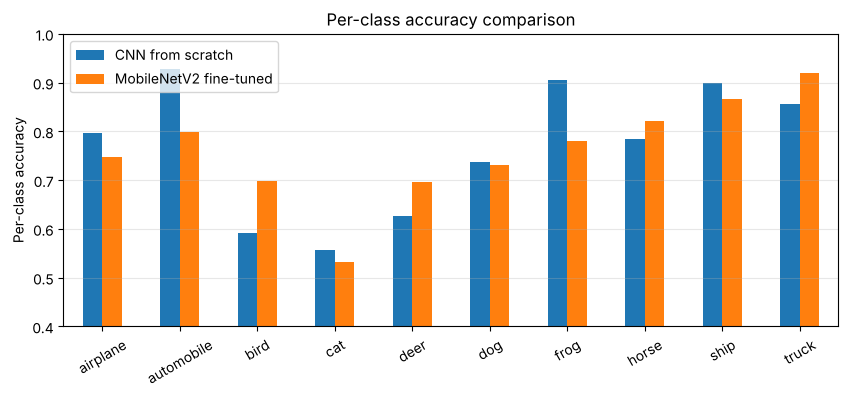

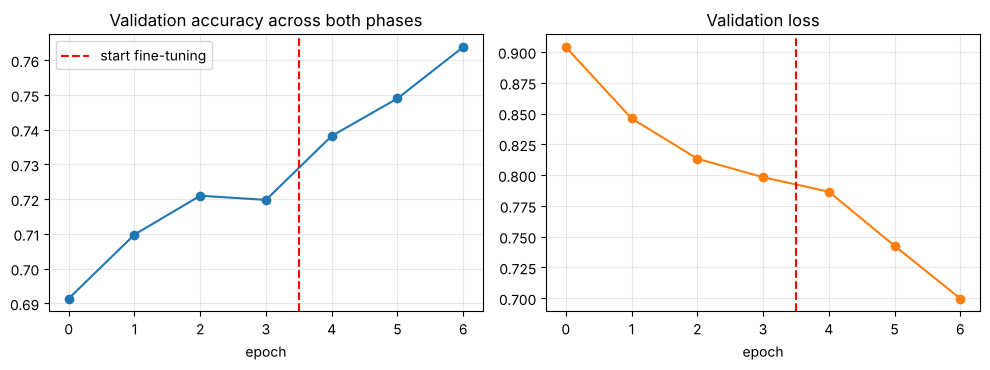

In [7]:
comp = pd.DataFrame({
    "Test accuracy": [accuracy_score(y_test, pred_cnn), acc1, acc2],
    "Macro F1": [f1_score(y_test, pred_cnn, average="macro"), None, f1_score(y_test, pred_tl, average="macro")],
    "Trainable params": [cnn.count_params(), trainable, sum(int(np.prod(v.shape)) for v in tl.trainable_weights)],
    "Train time (min)": [cnn_minutes if cnn_minutes else "see Day 6", round(t_frozen/60, 1), round((t_frozen + t_ft)/60, 1)]},
    index=["CNN from scratch (Day 6)", "MobileNetV2 — frozen base", "MobileNetV2 — fine-tuned"])
print(comp.round(4).to_string())
R["q18"] = {"scratch_acc": round(float(accuracy_score(y_test, pred_cnn)), 4), "frozen_acc": round(float(acc1), 4), "finetuned_acc": round(float(acc2), 4),
            "frozen_minutes": round(t_frozen/60, 1), "finetune_minutes": round(t_ft/60, 1), "finetuned_macro_f1": round(float(f1_score(y_test, pred_tl, average="macro")), 4),
            "scratch_macro_f1": round(float(f1_score(y_test, pred_cnn, average="macro")), 4), "source": source}

pc_cnn = confusion_matrix(y_test, pred_cnn).diagonal() / 1000; pc_tl = confusion_matrix(y_test, pred_tl).diagonal() / 1000
pd.DataFrame({"CNN from scratch": pc_cnn, "MobileNetV2 fine-tuned": pc_tl}, index=CLASSES).plot.bar(figsize=(10, 3.8), rot=30); plt.ylabel("Per-class accuracy"); plt.ylim(.4, 1); plt.title("Per-class accuracy comparison"); plt.grid(axis="y", alpha=.3); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(h1.history["val_accuracy"] + h2.history["val_accuracy"], "o-"); ax[0].axvline(len(h1.history["val_accuracy"]) - .5, color="r", ls="--", label="start fine-tuning"); ax[0].set(title="Validation accuracy across both phases", xlabel="epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h1.history["val_loss"] + h2.history["val_loss"], "o-", color="tab:orange"); ax[1].axvline(len(h1.history["val_loss"]) - .5, color="r", ls="--"); ax[1].set(title="Validation loss", xlabel="epoch"); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

---
# Module D practical task — the image classifier (objects & animals)
Task model: **fine-tuned MobileNetV2** (the transfer-learning model). Note: in this run the Day 6 CNN trained from scratch scored slightly *higher* overall (see the comparison above), so MobileNetV2 is not the best performer here. Evaluation: confusion matrix, classification report, and a **prediction visualisation** (green = correct, red = wrong, with confidence).

              precision    recall  f1-score   support

    airplane      0.797     0.747     0.771      1000
  automobile      0.900     0.799     0.846      1000
        bird      0.700     0.699     0.700      1000
         cat      0.665     0.532     0.591      1000
        deer      0.687     0.697     0.692      1000
         dog      0.690     0.731     0.710      1000
        frog      0.818     0.781     0.799      1000
       horse      0.753     0.821     0.785      1000
        ship      0.844     0.866     0.855      1000
       truck      0.747     0.919     0.824      1000

    accuracy                          0.759     10000
   macro avg      0.760     0.759     0.757     10000
weighted avg      0.760     0.759     0.757     10000



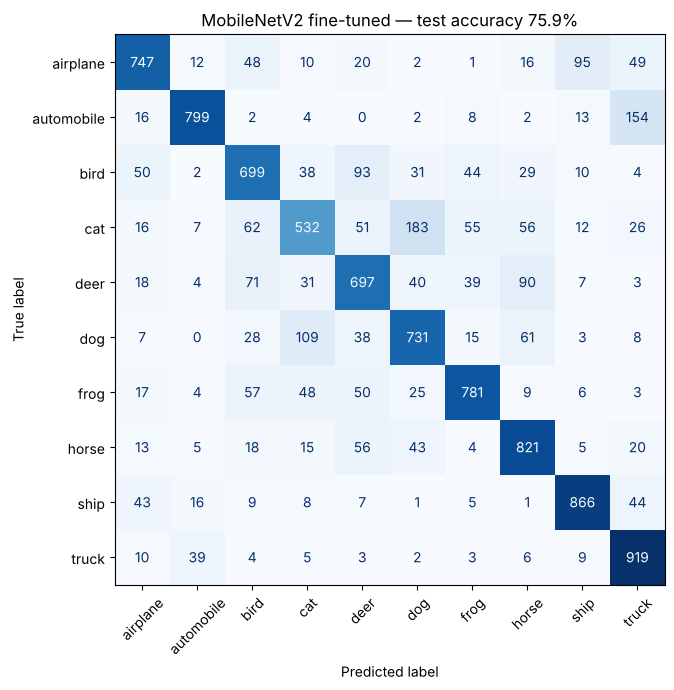

Most common confusion: 'cat' predicted as 'dog' (183 images) | best class: truck (91.9%) | weakest class: cat (53.2%)


In [8]:
print(classification_report(y_test, pred_tl, target_names=CLASSES, digits=3))
cm = confusion_matrix(y_test, pred_tl)
fig, ax = plt.subplots(figsize=(8, 7)); ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False); ax.set_title(f"MobileNetV2 fine-tuned — test accuracy {acc2:.1%}"); plt.tight_layout(); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0); a, b = np.unravel_index(off.argmax(), off.shape); pcl = cm.diagonal() / cm.sum(1)
print(f"Most common confusion: '{CLASSES[a]}' predicted as '{CLASSES[b]}' ({off[a, b]} images) | best class: {CLASSES[pcl.argmax()]} ({pcl.max():.1%}) | weakest class: {CLASSES[pcl.argmin()]} ({pcl.min():.1%})")
R["task"] = {"confusion": [CLASSES[a], CLASSES[b], int(off[a, b])], "best": [CLASSES[pcl.argmax()], round(float(pcl.max()), 3)], "worst": [CLASSES[pcl.argmin()], round(float(pcl.min()), 3)]}

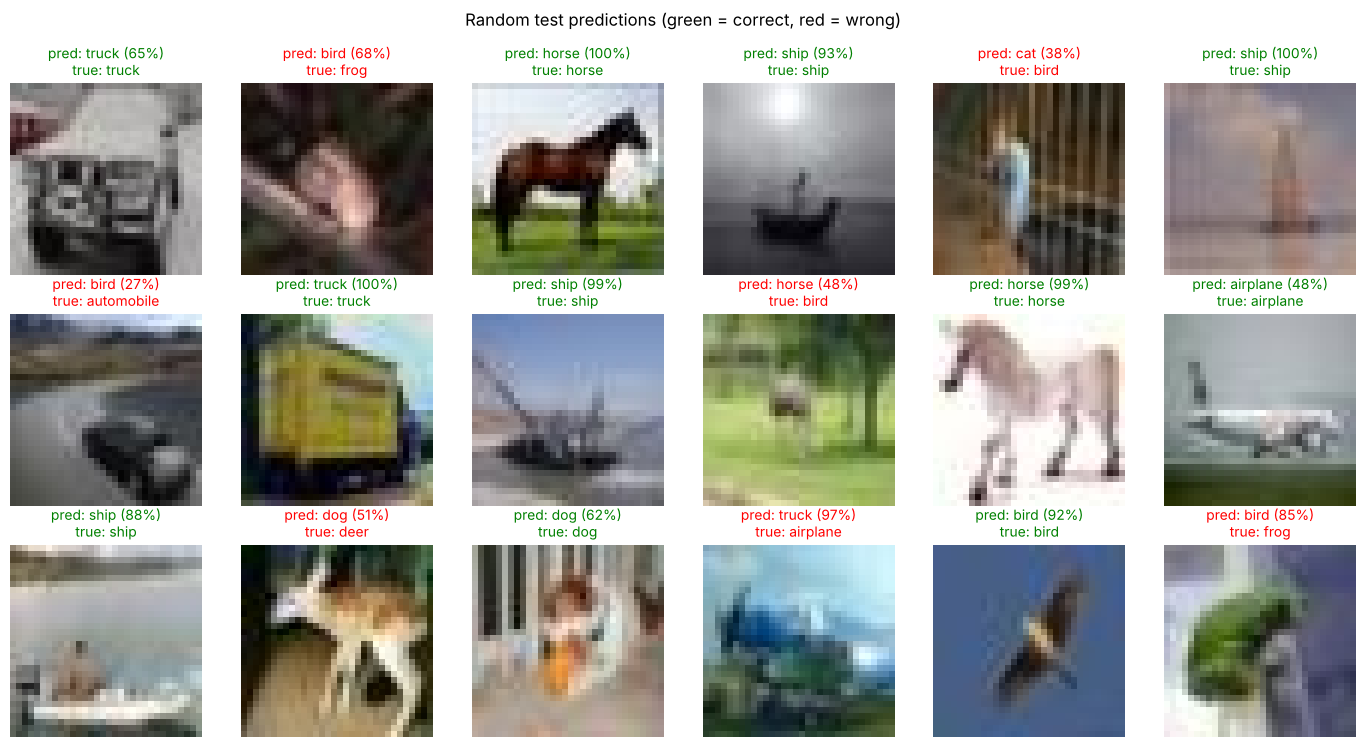

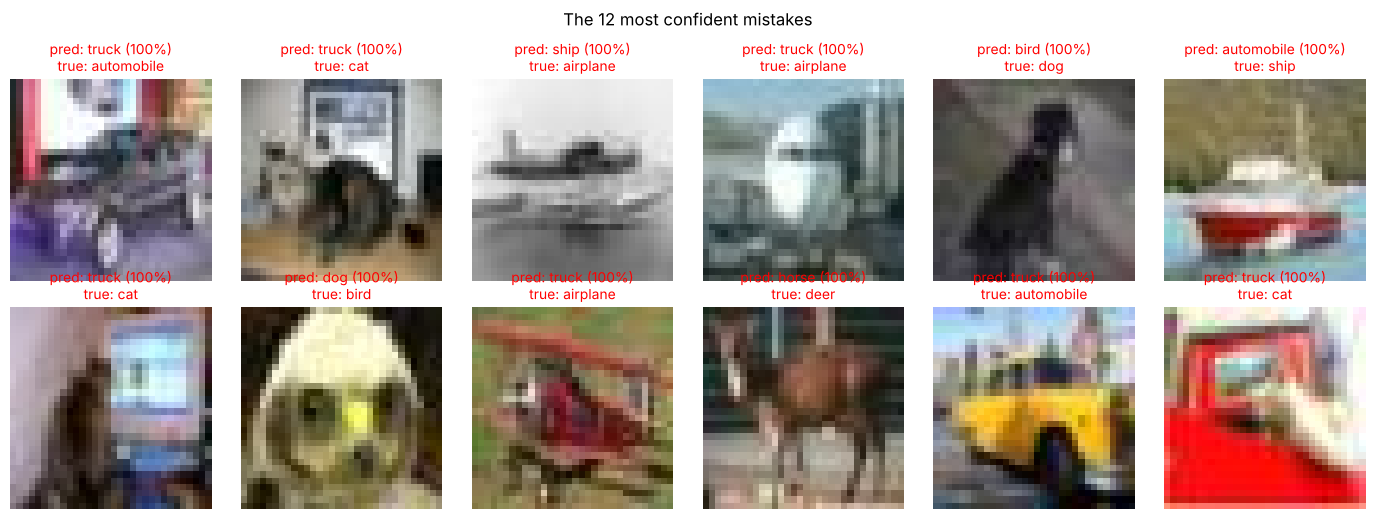

In [9]:
rng = np.random.default_rng(7); idx = rng.choice(len(x_test), 18, replace=False)
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), idx):
    conf = p_frozen_ft[i].max(); ok = pred_tl[i] == y_test[i]
    ax.imshow(x_test[i]); ax.axis("off"); ax.set_title(f"pred: {CLASSES[pred_tl[i]]} ({conf:.0%})\ntrue: {CLASSES[y_test[i]]}", color="green" if ok else "red", fontsize=10)
plt.suptitle("Random test predictions (green = correct, red = wrong)", y=.99); plt.tight_layout(); plt.show()

wrong = np.where(pred_tl != y_test)[0]; worst = wrong[np.argsort(-p_frozen_ft[wrong].max(1))[:12]]       # most confident mistakes
fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(x_test[i]); ax.axis("off"); ax.set_title(f"pred: {CLASSES[pred_tl[i]]} ({p_frozen_ft[i].max():.0%})\ntrue: {CLASSES[y_test[i]]}", color="red", fontsize=10)
plt.suptitle("The 12 most confident mistakes", y=.99); plt.tight_layout(); plt.show()

In [10]:
# predict a single "new" image the way you would in an app
def predict_image(img_uint8):
    p = tl.predict(img_uint8[None].astype("float32"), verbose=0)[0]; top = p.argsort()[::-1][:3]
    return [(CLASSES[k], float(p[k])) for k in top]
print("Top-3 for test image 0:", [(c, round(p, 3)) for c, p in predict_image(x_test[0])], "| true:", CLASSES[y_test[0]])

Top-3 for test image 0: [('ship', 0.642), ('airplane', 0.331), ('truck', 0.017)] | true: airplane


## Conclusions
* **Result in this run:** CNN from scratch **76.8%**, MobileNetV2 fine-tuned **75.9%**, MobileNetV2 frozen **71.7%**. Transfer learning did **not** beat the scratch CNN here.
* **Fine-tuning helped** the transfer model (+4 points over the frozen base) at the cost of extra training time; the learning rate must stay tiny.
* **Why transfer learning under-delivered:** CIFAR-10 images are only 32×32, so up-scaling them to 96×96 gives MobileNetV2 blurry inputs far from the 224×224 photos it was pre-trained on; I also trained only 4 + 3 epochs on a CPU. More fine-tuning epochs, a larger input size or unfreezing more layers would likely close the gap or overtake the scratch CNN. Transfer learning usually wins most when data is scarce or images are large; here we had 45,000 training images.
* Remaining errors cluster in visually similar classes (cat ↔ dog is the most common confusion; see the confusion matrix and the most-confident-mistakes grid).

### Summary of Day 7
| Idea | Takeaway |
|---|---|
| Multiclass | softmax + categorical cross-entropy; evaluate per class |
| Frozen base | cheap feature extraction, trains only the head |
| Fine-tuning | unfreeze top layers, tiny learning rate, re-compile |
| Evaluation | confusion matrix + prediction grids reveal *where* the model fails |

In [11]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
